# EDA — Hillstrom (2008) — campañas de e-mail en un e-commerce de indumentaria
**Proyecto Final · Lic. en Ciencia de Datos · Universidad CAECE**

64.000 clientes asignados al azar a tres grupos: email de productos masculinos, email de productos femeninos o sin email (control). Ventana de 2 semanas.

Notebook generado por `scripts/make_notebooks.py` a partir de `configs/hillstrom.yaml`. El análisis lo hace `uplift.eda` (genérico para cualquier dataset).

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT / "src"), str(ROOT)]
import numpy as np, pandas as pd
from IPython.display import Image, display
from uplift.dataset import load_config
pd.set_option("display.float_format", "{:.4f}".format)
cfg = load_config("hillstrom")
FIG = cfg.figures_dir
def show(name):
    p = FIG / f"{name}.png"
    if p.exists():
        display(Image(str(p)))
RUN = not (cfg.reports_dir / 'eda_summary.json').exists()

In [2]:
from uplift import eda
summary = eda.run(cfg) if RUN else json.load(open(cfg.reports_dir / 'eda_summary.json'))
pd.Series({k: v for k, v in summary['quality'].items() if not isinstance(v, dict)})

rows                   64000
columns                   13
memory_mb            21.1000
missing_total              0
duplicated_rows         6562
duplicates_sampled     False
data_contract             ok
dtype: object

## 1. Diseño experimental y balance de covariables
En un experimento aleatorizado las covariables deben estar balanceadas entre brazos (|SMD| < 0,1).

,arm,label,n,share
0,Sin email,control,21306,0.3329
1,Mens,mens,21307,0.3329
2,Womens,womens,21387,0.3342


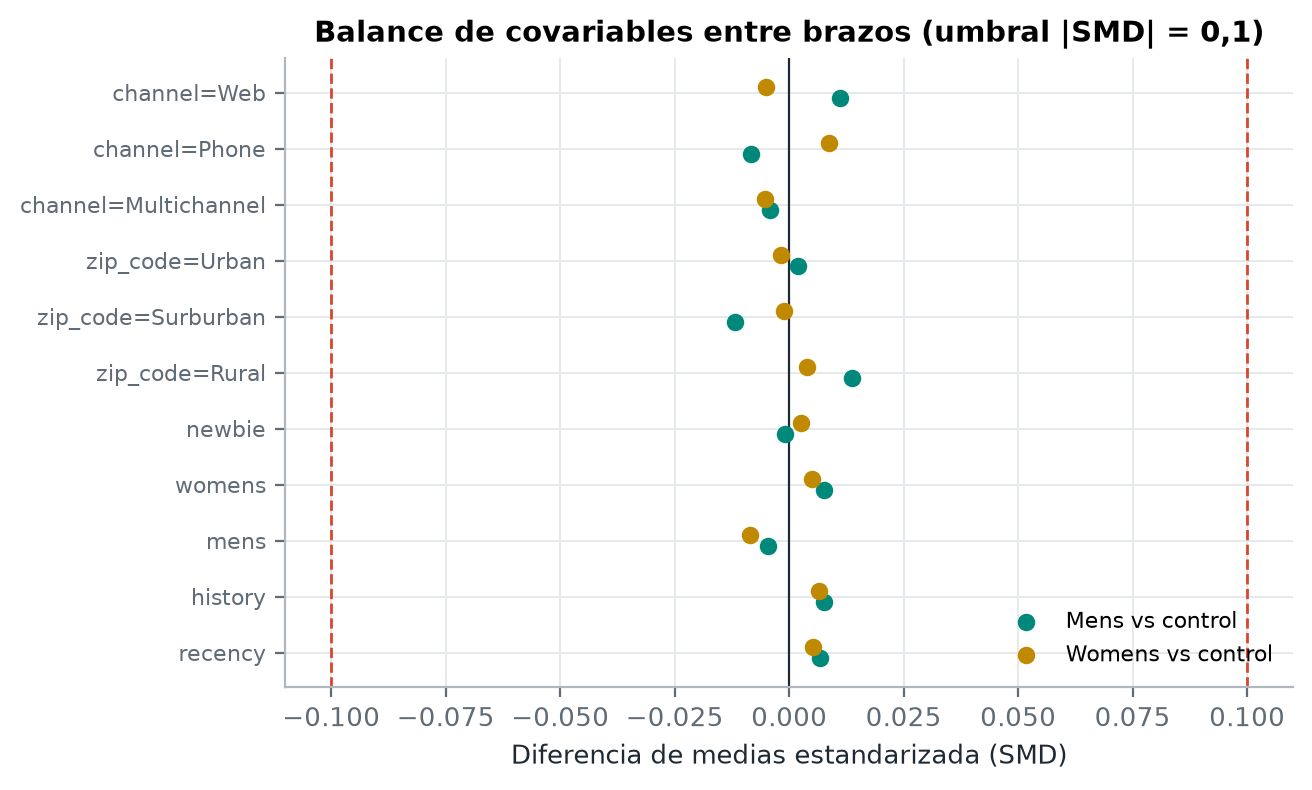

|SMD| máximo: 0.0137


In [3]:
display(pd.read_csv(cfg.tables_dir / 'eda_arm_counts.csv'))
show('eda_balance')
print('|SMD| máximo:', round(summary['max_abs_smd'], 4))

## 2. Efecto promedio de cada tratamiento (ATE)

,outcome,arm,n,mean,mean_lo,mean_hi,ate,ate_lo,ate_hi,relative_lift,p_value
0,visit,control,21306,0.1062,0.1020,0.1103,NaN,NaN,NaN,NaN,NaN
1,visit,mens,21307,0.1828,0.1776,0.1879,0.0766,0.0700,0.0832,0.7214,0.0000
2,visit,womens,21387,0.1514,0.1466,0.1562,0.0452,0.0389,0.0516,0.4261,0.0000
3,conversion,control,21306,0.0057,0.0047,0.0067,NaN,NaN,NaN,NaN,NaN
4,conversion,mens,21307,0.0125,0.0110,0.0140,0.0068,0.0050,0.0086,1.1884,0.0000
5,conversion,womens,21387,0.0088,0.0076,0.0101,0.0031,0.0015,0.0047,0.5433,0.0002
6,spend,control,21306,0.6528,0.4972,0.8084,NaN,NaN,NaN,NaN,NaN
7,spend,mens,21307,1.4226,1.1842,1.6610,0.7698,0.4851,1.0545,1.1793,0.0000
8,spend,womens,21387,1.0772,0.8746,1.2798,0.4244,0.1690,0.6799,0.6502,0.0011


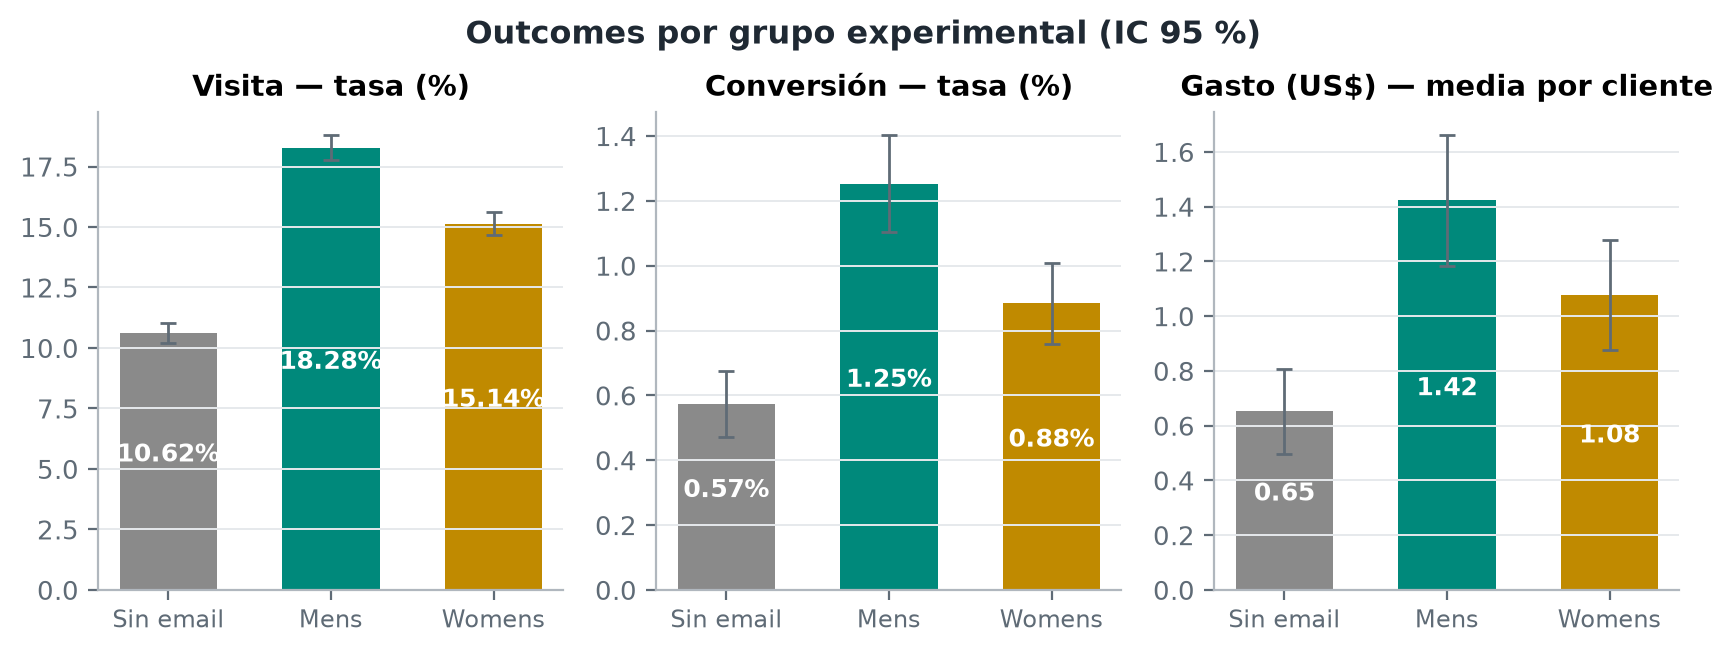

In [4]:
display(pd.read_csv(cfg.tables_dir / 'eda_ate.csv'))
show('eda_rates_by_group')

## 3. Distribuciones y correlaciones

,variable,mean,median,std,min,max,skewness,n_unique,zero_share,outliers_iqr
0,recency,5.7637,6.0000,3.5076,1.0000,12.0000,0.1393,12,0.0000,0
1,history,242.0857,158.1100,256.1586,29.9900,3345.9300,2.4237,34833,0.0000,3593
2,spend,1.0509,0.0000,15.0364,0.0000,499.0000,20.5901,429,0.9910,578


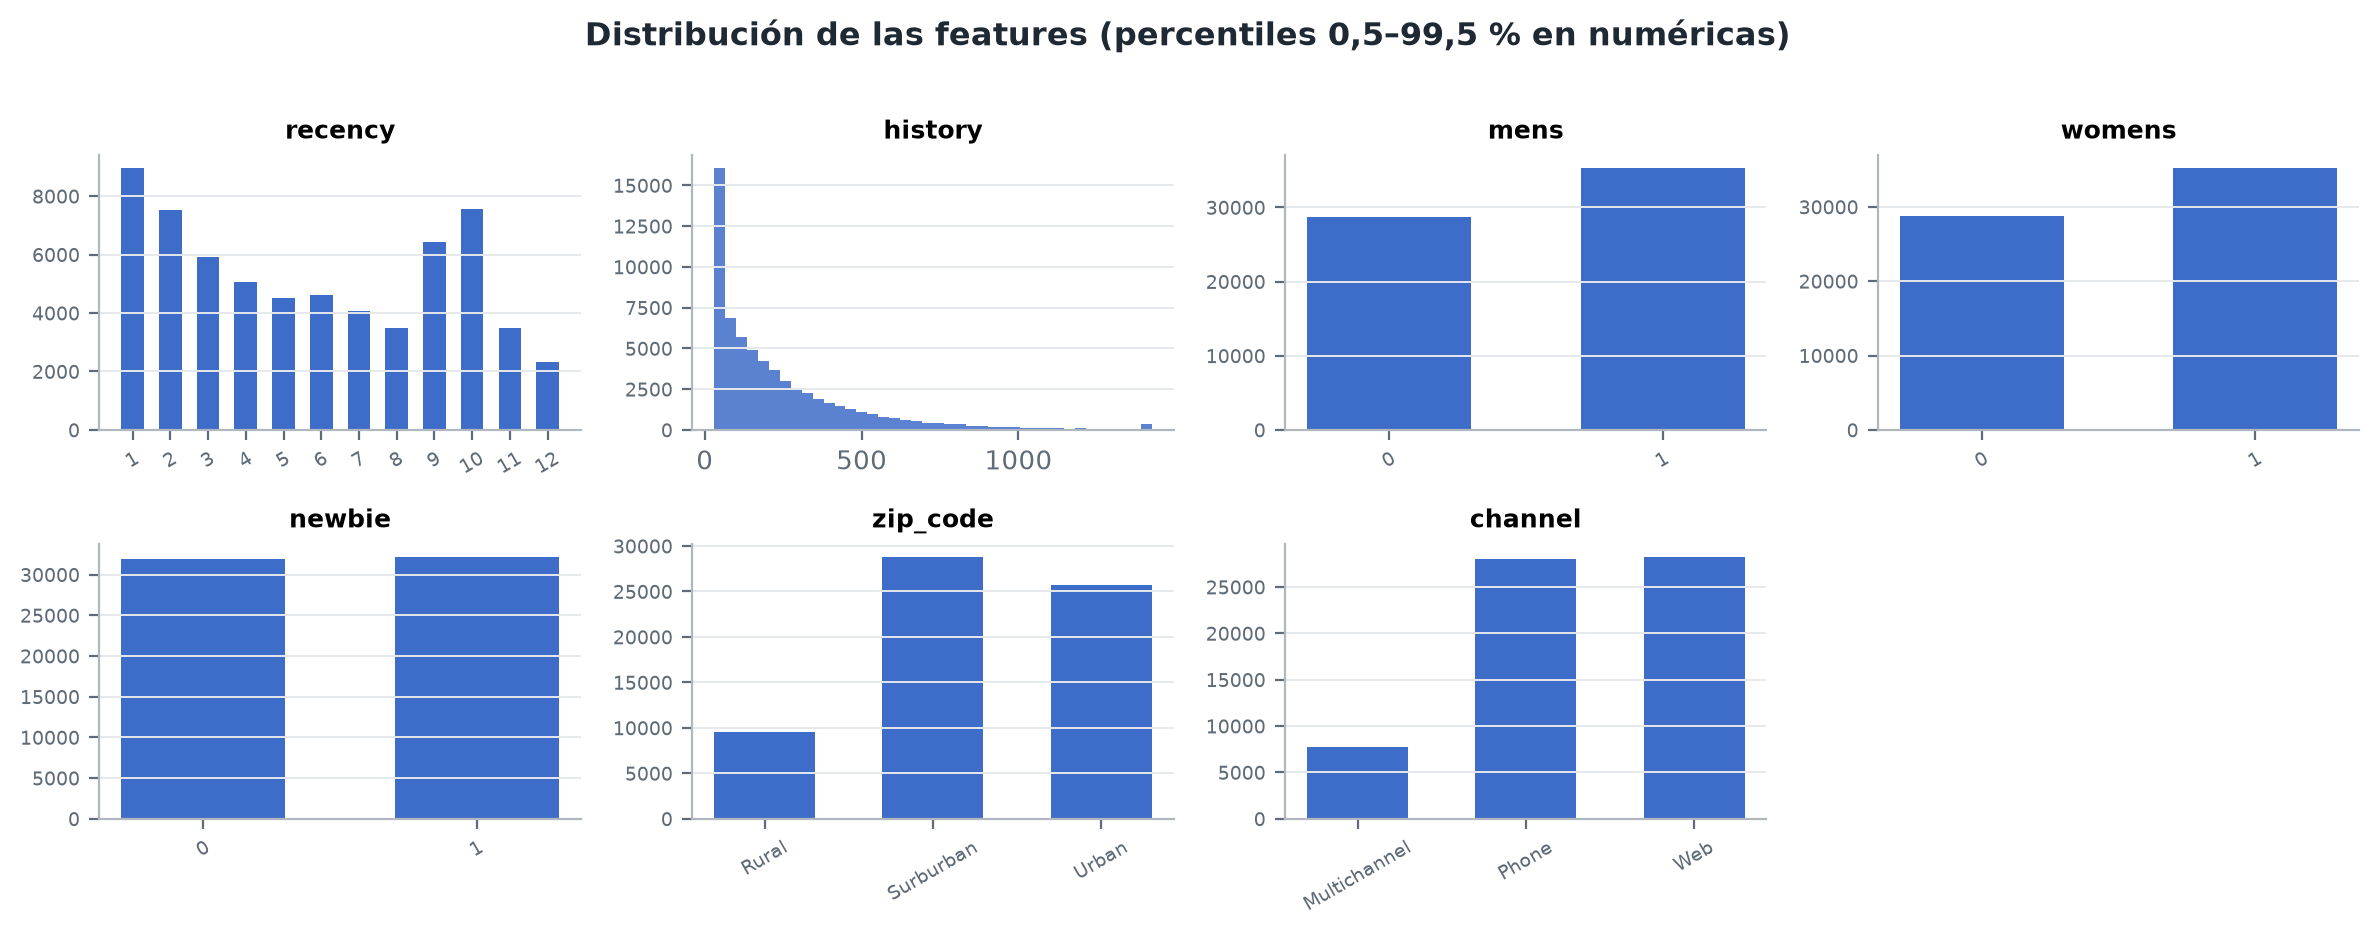

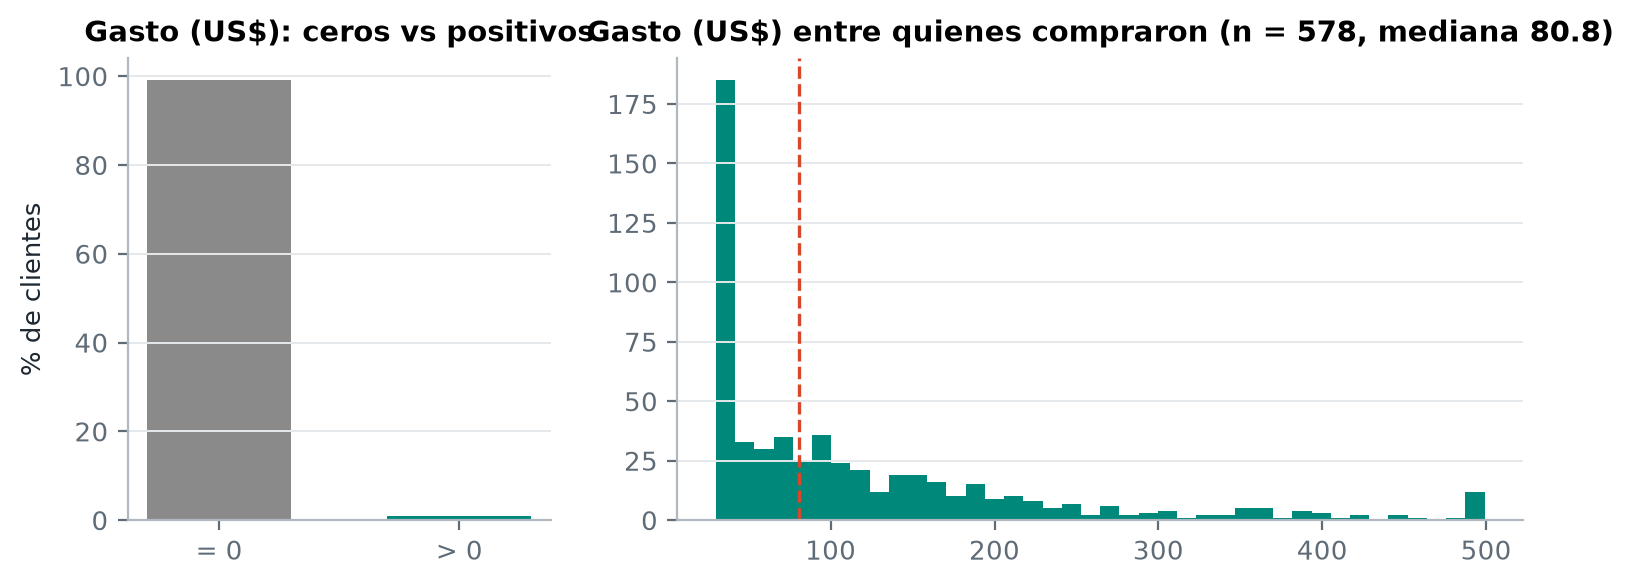

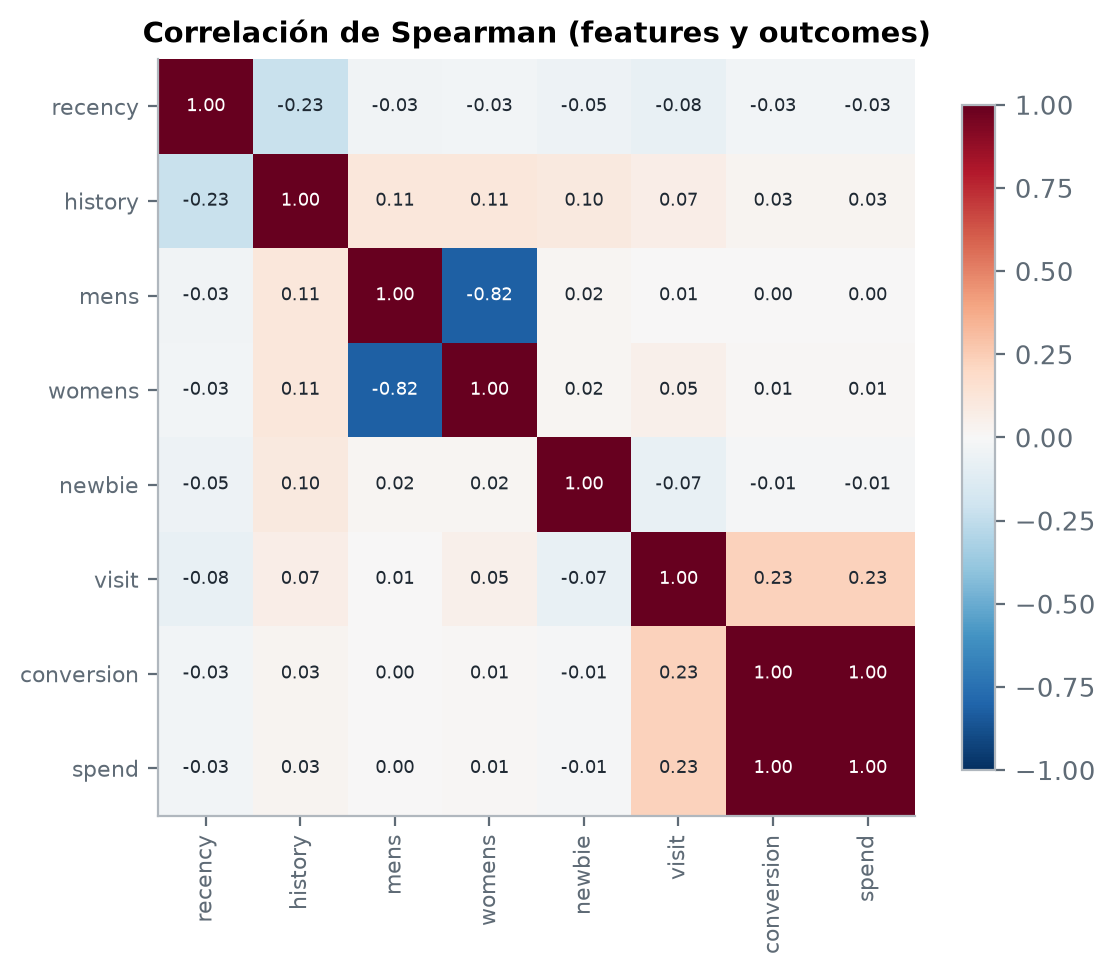

[{'a': 'mens', 'b': 'womens', 'rho': -0.8169427039940474},
 {'a': 'conversion', 'b': 'spend', 'rho': 0.9999864613254928}]

In [5]:
display(pd.read_csv(cfg.tables_dir / 'eda_numeric_summary.csv'))
show('eda_distributions')
show('eda_outcome_distribution')
show('eda_correlation')
summary['strong_correlations']

## 4. Heterogeneidad del efecto
Si el efecto del tratamiento varía entre tramos de las features, el CATE individual es estimable (test Q de Cochran sobre los ATE por tramo).

,feature,arm,Q,df,p_value,ate_range
0,categoria,womens,97.3377,2,0.0000,0.0629
1,womens,womens,94.2133,1,0.0000,0.0620
2,mens,womens,64.4239,1,0.0000,0.0522
3,categoria,mens,23.2366,2,0.0000,0.0653
4,history,mens,7.5155,4,0.1110,0.0286
5,history,womens,6.3002,4,0.1778,0.0204
6,recency,mens,4.6473,4,0.3254,0.0189
7,womens,mens,3.9214,1,0.0477,0.0134
8,zip_code,womens,3.6309,2,0.1628,0.0198
9,recency,womens,2.8592,4,0.5817,0.0195


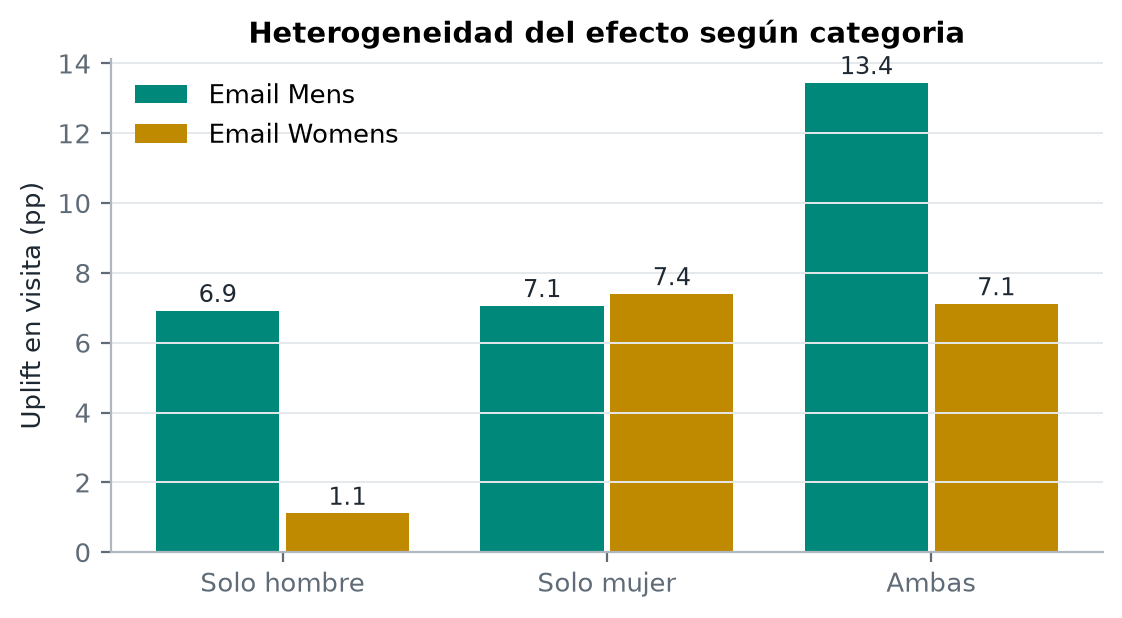

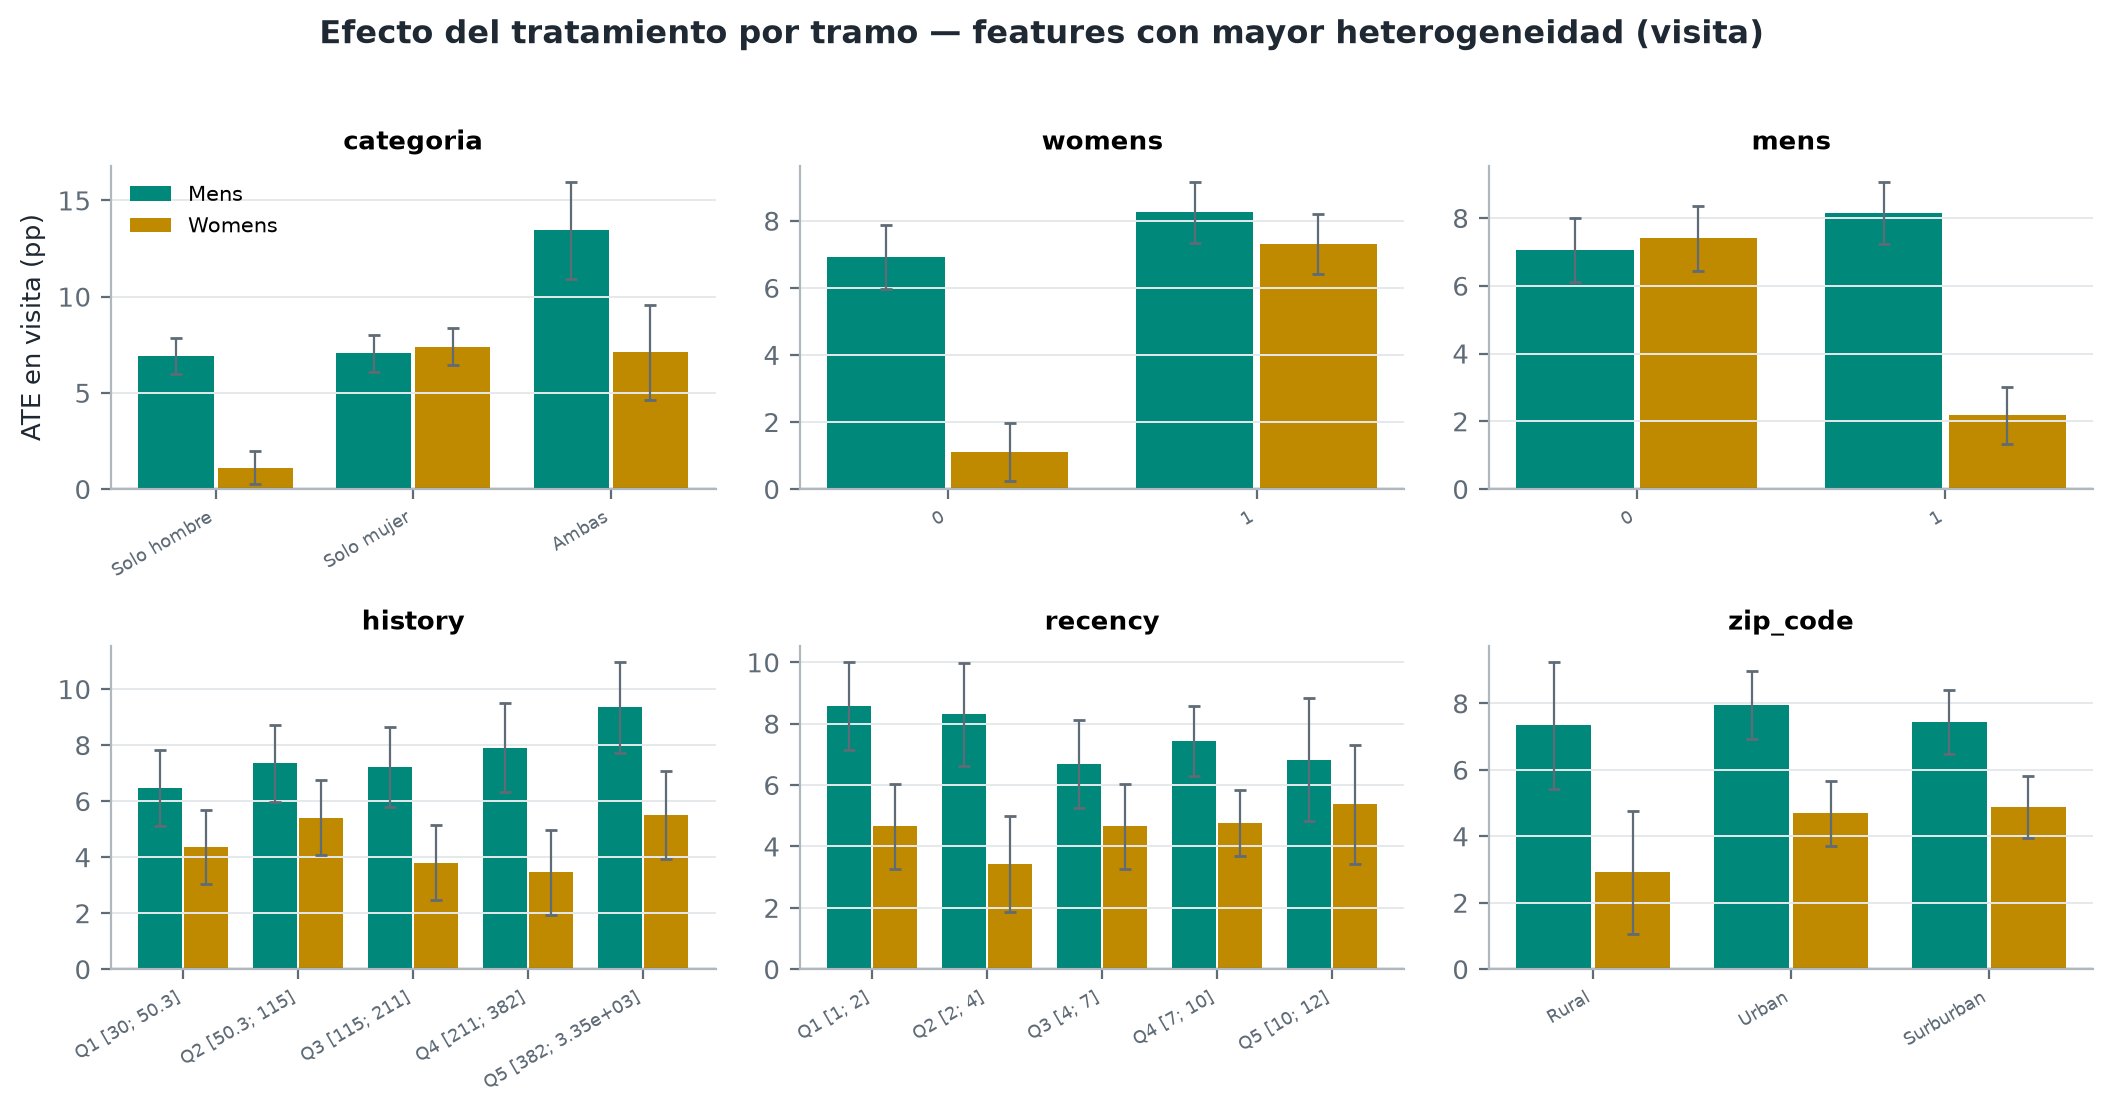

In [6]:
display(pd.read_csv(cfg.tables_dir / 'eda_heterogeneity_test_visit.csv').head(10))
show('eda_heterogeneity')
show('eda_heterogeneity_features')

## 5. Veredicto de viabilidad

In [7]:
display(pd.DataFrame(summary['viability']))
print('VIABLE' if summary['viable'] else 'REVISAR')

,criterio,aprobado,detalle
0,Sin valores faltantes,True,0 faltantes
1,Contrato de datos (dominios y restricciones ló...,True,ok
2,"Aleatorización válida (|SMD| < 0,1 en todas la...",True,|SMD| máx. = 0.014
3,"Efecto promedio significativo en visit (p < 0,05)",True,mens: +7.66 pp (p=5.7e-112); womens: +4.52 pp ...
4,Heterogeneidad del efecto detectable (Cochran ...,True,5 de 16 pares feature × tratamiento
5,Eventos suficientes por brazo (≥ 100 en cada o...,True,mínimo = 122


VIABLE
